# DB-scan 


In [77]:
import profile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score,davies_bouldin_score

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut
profile_df = pd.read_csv("../../data/processed/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)


profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.0,0.251724,0.328571,0.410714,0.0,0.0,0.0
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.0,0.389655,0.714286,0.375000,0.0,0.0,0.0
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.0,0.341379,0.500000,0.384058,0.0,0.0,0.0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.0,0.396552,0.357143,0.300000,0.0,0.0,0.0
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.0,0.220000,1.416667,0.375000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0


In [78]:
profile_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 37 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   subject_id                        4383 non-null   int64  
 1   ACS_acute_ischemic                4383 non-null   int64  
 2   Chronic_ischemic                  4383 non-null   int64  
 3   Heart_failure                     4383 non-null   int64  
 4   Valvular_nonrheumatic             4383 non-null   int64  
 5   Myocarditis_or_cardiomyopathy     4383 non-null   int64  
 6   Pericardial_disease               4383 non-null   int64  
 7   Endocarditis                      4383 non-null   int64  
 8   Cardiac_arrest                    4383 non-null   int64  
 9   Arrhythmias_or_conduction         4383 non-null   int64  
 10  number_of_hadm                    4383 non-null   int64  
 11  gender                            4383 non-null   int64  
 12  age   

In [79]:
#correletion
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

#print the feautures with correlation higer than 0.8
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.8)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_antibiotics_count', 'sensitive_microorganism_ratio')]

## some consideration
### sensitve_micro_ratio and unique-antibioti_count have a correlation>0.8 , for our analysis sensitve_micro_ratio is more signficant, I drop the other


In [80]:
# Drop highly correlated features
profile_df= profile_df.drop(columns=['unique_antibiotics_count'])

#mask categorical columns
categorical_cols = profile_df['gender','ACS_acute_ischemic','Chronic_ischemic','Heart_failure','Valvular_nonrheumatic','Myocarditis_or_cardiomyopathy','Pericardial_disease','Endocarditis','Cardiac_arrest','Arrhythmias_or_conduction']
profile_df=profile_df(~categorical_cols)
# Scale with min-max scaler
numeric_cols = profile_df.select_dtypes(include=['float64', 'int64']).columns.tolist()

#remoive columns with more than 0.8 of correlation



Colonne usate per il clustering: ['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_wbc count', 'max_platelet count', 'max_white blood cells', 'abnormal_lab_event_ratio', 'resistant_microorganism_ratio', 'intermediate_microorganism_ratio', 'sensitive_microorganism_ratio']
Numero di features: 25


In [81]:
scaler = MinMaxScaler()
X = scaler.fit_transform(profile_df[numeric_cols].values)



In [82]:
#compute pairwise distance and distance matrix
dist = pdist(X, 'euclidean') #pair wise distance
print (dist)
dist = squareform(dist) #distance matrix given the vector dist
print()
print(dist)

[0.56221119 0.48182928 0.73509816 ... 0.12987013 0.18181818 0.31168831]

[[0.         0.56221119 0.48182928 ... 0.86507982 0.88626681 0.86780508]
 [0.56221119 0.         0.61978205 ... 0.70838325 0.72018962 0.73134444]
 [0.48182928 0.61978205 0.         ... 0.90698608 0.91623687 0.92503059]
 ...
 [0.86507982 0.70838325 0.90698608 ... 0.         0.12987013 0.18181818]
 [0.88626681 0.72018962 0.91623687 ... 0.12987013 0.         0.31168831]
 [0.86780508 0.73134444 0.92503059 ... 0.18181818 0.31168831 0.        ]]


## strategia 
### parto da min-sample 5, guardo il gomito e metto eps=0.3 : troppi cluster allora umento min_sample 
### con 8 min sapmle ancora troppi cluster
### provo 10 non va ancora 
### arrivata a 15 ho meno cluster ma anche con la scelta igliore di eps, troppo sbilanciati, aumenta ancora min_sample

In [93]:
k = 5
kth_distances = list()
for d in dist:
    index_kth_distance = np.argsort(d)[k]
    kth_distances.append(d[index_kth_distance])

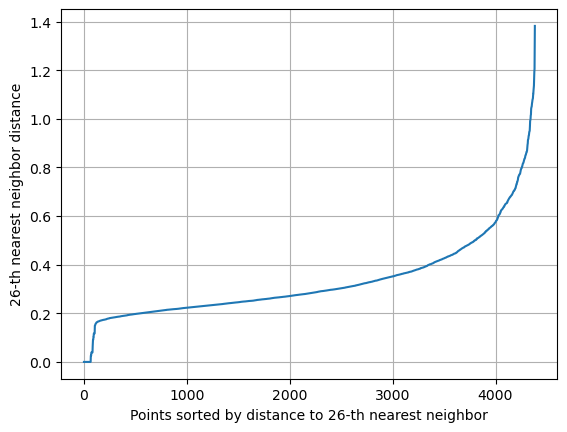

In [94]:
#plot the sorted kth distances witj grid 
kth_distances = np.array(kth_distances)
kth_distances = np.sort(kth_distances)
plt.plot(kth_distances)
plt.xlabel('Points sorted by distance to {}-th nearest neighbor'.format(k))
plt.ylabel('{}-th nearest neighbor distance'.format(k))
plt.grid()
plt.show()

In [100]:
# Funzione aggiornata per calcolare solo il Silhouette Score
epsList = [  0.4 ]
best_ms, best_eps, best_silhouette = 0, 0, -1.0

for min_samples in range(5, 50):
    for eps in epsList:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        dbscan.fit(X)
        
        # Ottieni i cluster generati
        unique_labels, counts = np.unique(dbscan.labels_, return_counts=True)
        clusters = len(unique_labels)
        
        # Verifica il numero di cluster (escludendo noise se presente)
        if clusters > 1:
            silhouette = silhouette_score(X, dbscan.labels_)
            print(f'min_samples: {min_samples}, eps: {eps}, Silhouette Score: {silhouette:.4f}')
            
            # Aggiorna il miglior punteggio se necessario
            if silhouette > best_silhouette:
                best_silhouette = silhouette
                best_ms = min_samples
                best_eps = eps

print(f'\nBest min_samples: {best_ms}, Best eps: {best_eps}, Best Silhouette Score: {best_silhouette:.4f}')

min_samples: 5, eps: 0.4, Silhouette Score: 0.3948
min_samples: 6, eps: 0.4, Silhouette Score: 0.3968
min_samples: 7, eps: 0.4, Silhouette Score: 0.3936
min_samples: 8, eps: 0.4, Silhouette Score: 0.3926
min_samples: 9, eps: 0.4, Silhouette Score: 0.3910
min_samples: 10, eps: 0.4, Silhouette Score: 0.3814
min_samples: 11, eps: 0.4, Silhouette Score: 0.3687
min_samples: 12, eps: 0.4, Silhouette Score: 0.3675
min_samples: 13, eps: 0.4, Silhouette Score: 0.3664
min_samples: 14, eps: 0.4, Silhouette Score: 0.3644
min_samples: 15, eps: 0.4, Silhouette Score: 0.3626
min_samples: 16, eps: 0.4, Silhouette Score: 0.3619
min_samples: 17, eps: 0.4, Silhouette Score: 0.3616
min_samples: 18, eps: 0.4, Silhouette Score: 0.3610
min_samples: 19, eps: 0.4, Silhouette Score: 0.3609
min_samples: 20, eps: 0.4, Silhouette Score: 0.3600
min_samples: 21, eps: 0.4, Silhouette Score: 0.3586
min_samples: 22, eps: 0.4, Silhouette Score: 0.3579
min_samples: 23, eps: 0.4, Silhouette Score: 0.3570
min_samples: 24, 

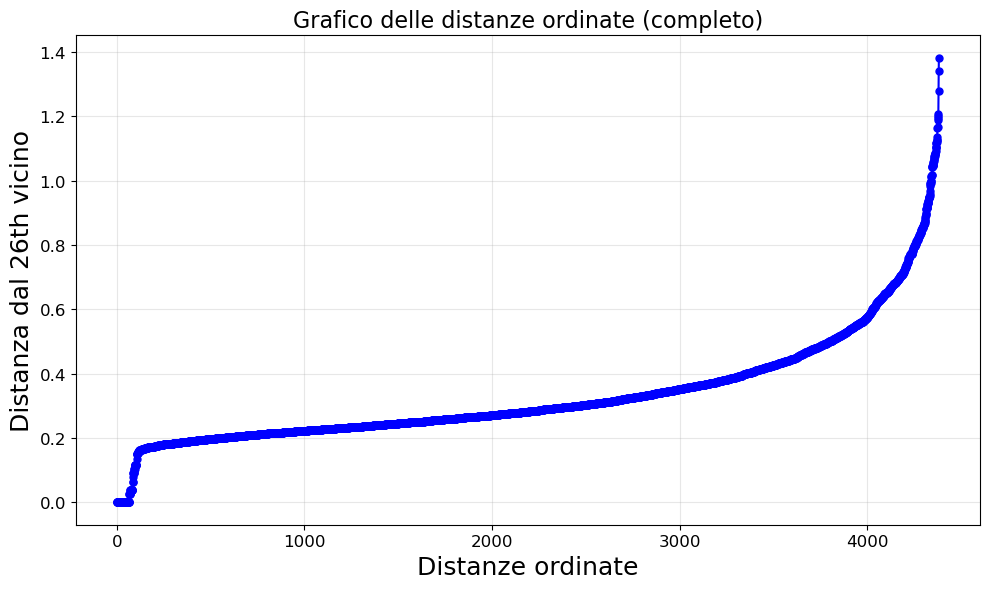

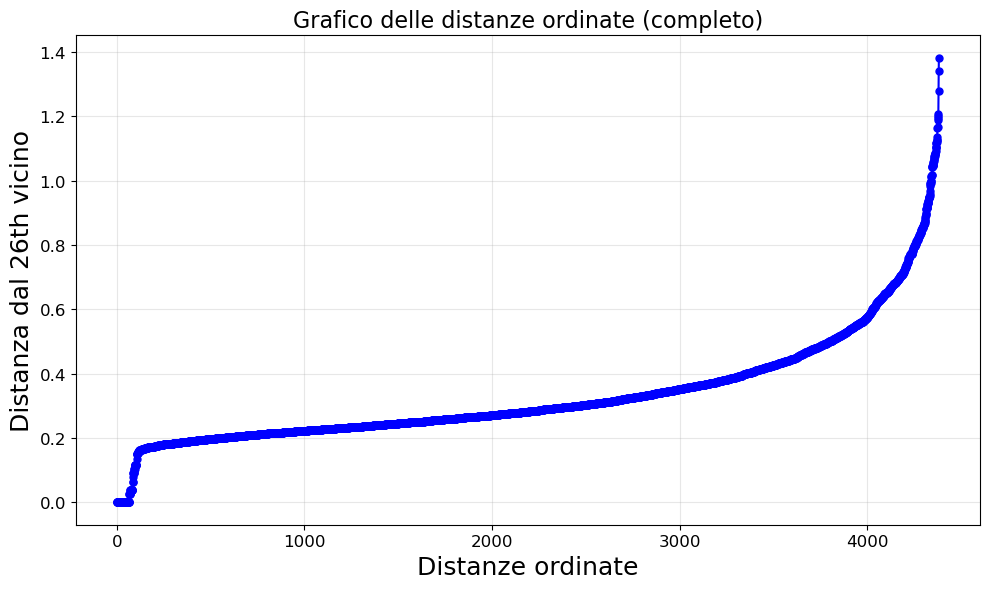

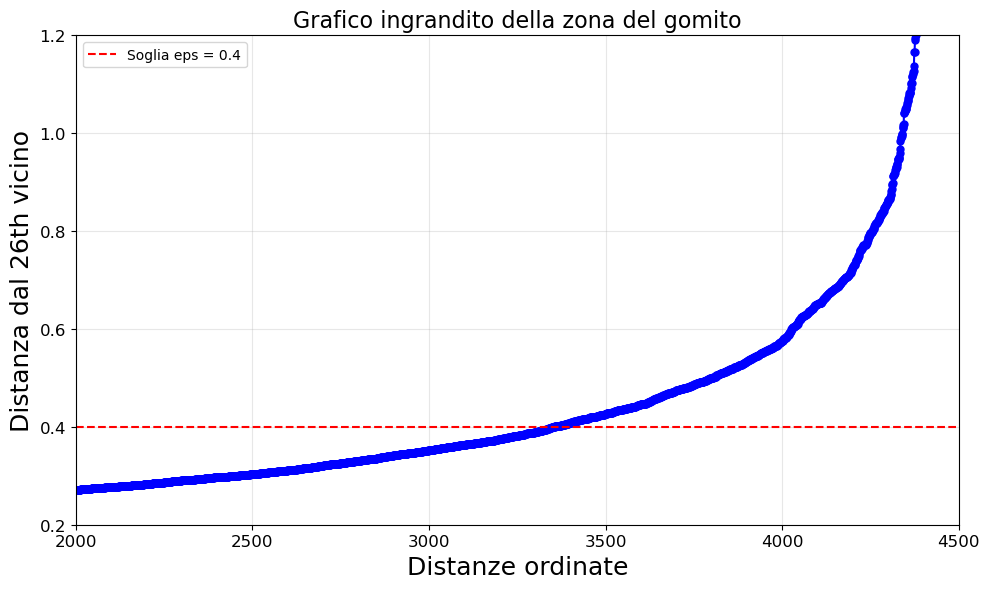

In [101]:
# Plot completo delle distanze ordinate
plt.figure(figsize=(10, 6))
plt.plot(range(0, len(kth_distances)), sorted(kth_distances), color='blue', linestyle='-', marker='o', markersize=5)
plt.ylabel('Distanza dal %sth vicino' % k, fontsize=18)
plt.xlabel('Distanze ordinate', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.title("Grafico delle distanze ordinate (completo)", fontsize=16)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot ingrandito della zona del gomito
plt.figure(figsize=(10, 6))
plt.plot(range(0, len(kth_distances)), sorted(kth_distances), color='blue', linestyle='-', marker='o', markersize=5)
plt.xlim(2000, 4500)  # Limita l'asse X per concentrarti sui primi punti
plt.ylim(0.2, 1.2)  # Limita l'asse Y per concentrarti sulla zona del gomito
plt.ylabel('Distanza dal %sth vicino' % k, fontsize=18)
plt.xlabel('Distanze ordinate', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=12)
plt.axhline(y=best_eps, color='red', linestyle='--', label=f'Soglia eps = {best_eps}')
plt.title("Grafico ingrandito della zona del gomito", fontsize=16)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [102]:
# Raffina la ricerca di eps attorno al valore migliore trovato
for eps_ in np.arange(0.3,0.7,0.01):    
    dbscan = DBSCAN(eps=eps_, min_samples=best_ms)
    dbscan.fit(X)
    np.unique(dbscan.labels_, return_counts=True)
    clusters = len(np.unique(dbscan.labels_))
    
    if clusters > 1:
        silhouette = silhouette_score(X, dbscan.labels_)
        davies_bouldin = davies_bouldin_score(X, dbscan.labels_)
        print('minsample = %s, eps= %s => K= %s, Silhouette %s, Davies-Bouldin %s' % 
              (best_ms, eps_, clusters, silhouette, davies_bouldin))
        
        # Aggiorna best_eps se troviamo un silhouette migliore
        if silhouette > best_silhouette:
            best_silhouette = silhouette
            best_eps = eps_
            best_ms = best_ms
    else:
        print('minsample = %s, eps= %s => K= %s, Silhouette N/A (solo 1 cluster)' % (best_ms, eps_, clusters))

print(f'\n=== Parametri finali migliori ===')
print(f'Best min_samples: {best_ms}')
print(f'Best eps: {best_eps}')
print(f'Best Silhouette Score: {best_silhouette:.4f}')

PRIMA del raffinamento:
  best_ms = 27, best_eps = 0.4, best_silhouette = 0.4102

minsample = 27, eps= 0.1 => K= 2, Silhouette -0.0034554545092062424, Davies-Bouldin 0.9693035152643154
minsample = 27, eps= 0.15000000000000002 => K= 3, Silhouette -0.20675775507790004, Davies-Bouldin 1.5487850487860921
minsample = 27, eps= 0.20000000000000004 => K= 2, Silhouette 0.03880179025435745, Davies-Bouldin 2.1684286565231736
minsample = 27, eps= 0.25000000000000006 => K= 2, Silhouette 0.1846522204054865, Davies-Bouldin 2.5300424525727196
minsample = 27, eps= 0.30000000000000004 => K= 2, Silhouette 0.2770646112840328, Davies-Bouldin 2.3888679274157454
minsample = 27, eps= 0.3500000000000001 => K= 2, Silhouette 0.3567477707177739, Davies-Bouldin 2.16250350016709
minsample = 27, eps= 0.40000000000000013 => K= 2, Silhouette 0.41017401567505984, Davies-Bouldin 1.9241754075455246
minsample = 27, eps= 0.45000000000000007 => K= 4, Silhouette 0.38360479640335626, Davies-Bouldin 1.60292664631295
minsample 

### osservo che con il best eps trovato (eps=0.65) avrei solo 1 cluster oltre al noise. Sceglo di prendere il secondo best eps =0.6

In [103]:
best_eps=0.6
dbscan = DBSCAN(eps= best_eps,min_samples= best_ms)
dbscan.fit(X)

,eps,0.6
,min_samples,27
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


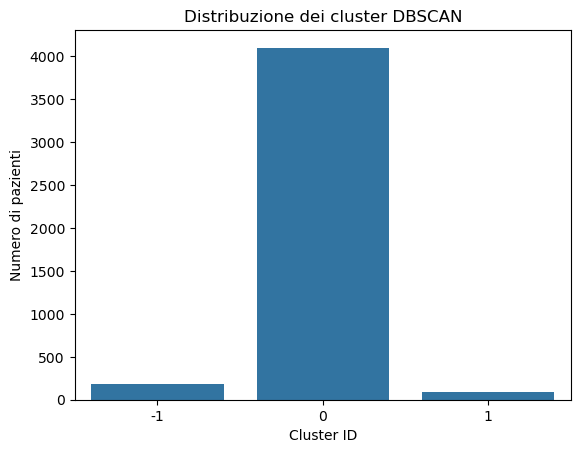

In [104]:
# Aggiungi i cluster assegnati al DataFrame
profile_df['cluster'] = dbscan.labels_

# Ora puoi creare il grafico
sns.countplot(x='cluster', data=profile_df)
plt.title("Distribuzione dei cluster DBSCAN")
plt.xlabel("Cluster ID")
plt.ylabel("Numero di pazienti")
plt.show()

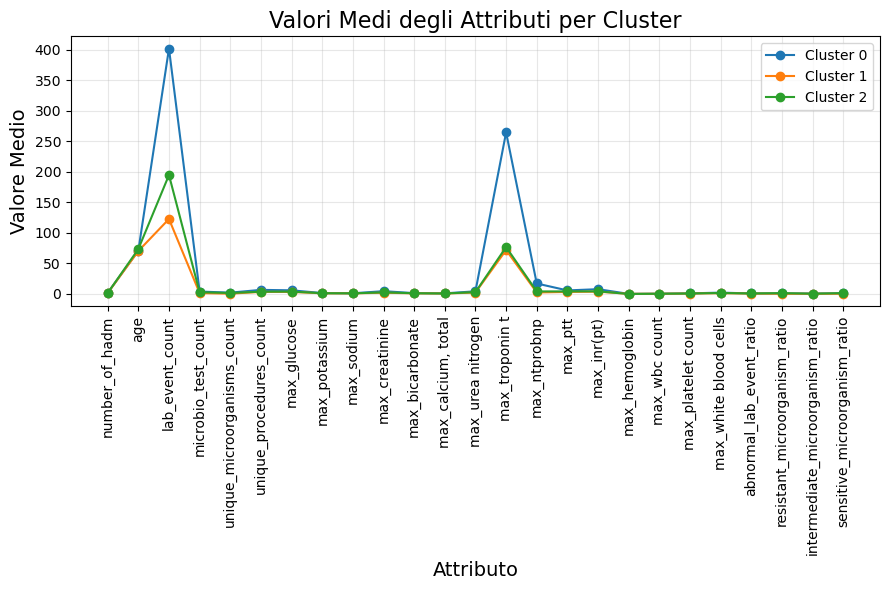

In [122]:
# Aggiungi 1 ai cluster per evitare valori negativi (noise diventa 0)
profile_df["cluster"] = dbscan.labels_ + 1

# Calcola le medie per cluster, escludendo subject_id
numeric_cols_for_plot = [col for col in numeric_cols if col not in ['subject_id', 'cluster']]
means = profile_df.groupby('cluster')[numeric_cols_for_plot].mean()

# Crea un grafico a linee per ciascun cluster
plt.figure(figsize=(9, 6))
for cluster in means.index:
    plt.plot(means.columns, means.loc[cluster], marker='o', label=f'Cluster {cluster}')

plt.xlabel('Attributo', fontsize=14)
plt.ylabel('Valore Medio', fontsize=14)
plt.title('Valori Medi degli Attributi per Cluster', fontsize=16)
plt.legend()
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

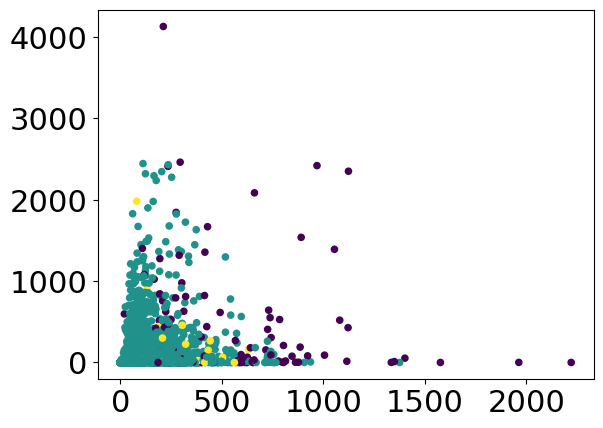

In [119]:


# Ora puoi creare il grafico
plt.scatter(profile_df['lab_event_count'], profile_df['max_troponin t'], c=dbscan.labels_, s=20)
plt.tick_params(axis='both', which='major', labelsize=22)
plt.show()

# Analisi Approfondita dei Cluster

Analizziamo i cluster creati con DBSCAN per comprendere le caratteristiche dei diversi gruppi di pazienti.

In [123]:
# 1. Statistiche generali sui cluster
print("=" * 60)
print("STATISTICHE GENERALI SUI CLUSTER")
print("=" * 60)

# Conta i pazienti per cluster
cluster_counts = profile_df['cluster'].value_counts().sort_index()
print(f"\nNumero totale di pazienti: {len(profile_df)}")
print(f"Numero di cluster (incluso noise): {len(cluster_counts)}")
print("\nDistribuzione pazienti per cluster:")
for cluster_id, count in cluster_counts.items():
    percentage = (count / len(profile_df)) * 100
    cluster_name = "Noise" if cluster_id == 0 else f"Cluster {cluster_id}"
    print(f"  {cluster_name}: {count} pazienti ({percentage:.2f}%)")

# Calcola metriche di qualità
if len(cluster_counts) > 1:
    # Escludiamo il noise (cluster 0) per calcolare le metriche
    non_noise_mask = profile_df['cluster'] != 0
    if non_noise_mask.sum() > 0:
        silhouette = silhouette_score(X[non_noise_mask], profile_df.loc[non_noise_mask, 'cluster'])
        davies_bouldin = davies_bouldin_score(X[non_noise_mask], profile_df.loc[non_noise_mask, 'cluster'])
        print(f"\nMetriche di qualità (escludendo noise):")
        print(f"  Silhouette Score: {silhouette:.4f} (range: [-1, 1], migliore se vicino a 1)")
        print(f"  Davies-Bouldin Index: {davies_bouldin:.4f} (migliore se basso)")

STATISTICHE GENERALI SUI CLUSTER

Numero totale di pazienti: 4383
Numero di cluster (incluso noise): 3

Distribuzione pazienti per cluster:
  Noise: 187 pazienti (4.27%)
  Cluster 1: 4101 pazienti (93.57%)
  Cluster 2: 95 pazienti (2.17%)

Metriche di qualità (escludendo noise):
  Silhouette Score: 0.5551 (range: [-1, 1], migliore se vicino a 1)
  Davies-Bouldin Index: 0.7177 (migliore se basso)


In [107]:
#save the column cluster in  the profile
labels = dbscan.labels_
profile_df['cluster'] = labels
profile_df


,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_inr(pt),max_hemoglobin,max_wbc count,max_platelet count,max_white blood cells,abnormal_lab_event_ratio,resistant_microorganism_ratio,intermediate_microorganism_ratio,sensitive_microorganism_ratio,cluster
0,10000980,1,0,1,0,0,0,0,0,0,...,2.0,-0.475000,0.0,0.251724,0.328571,0.410714,0.0,0.0,0.0,0
1,10002013,1,0,0,0,0,0,0,0,0,...,0.5,0.025000,0.0,0.389655,0.714286,0.375000,0.0,0.0,0.0,0
2,10002155,1,0,0,0,0,0,0,0,0,...,10.5,0.125000,0.0,0.341379,0.500000,0.384058,0.0,0.0,0.0,0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,-0.075000,0.0,0.396552,0.357143,0.300000,0.0,0.0,0.0,0
4,10007058,1,0,0,0,0,0,0,0,0,...,1.5,-0.315789,0.0,0.220000,1.416667,0.375000,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4378,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0
4379,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0
4380,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0
4381,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0


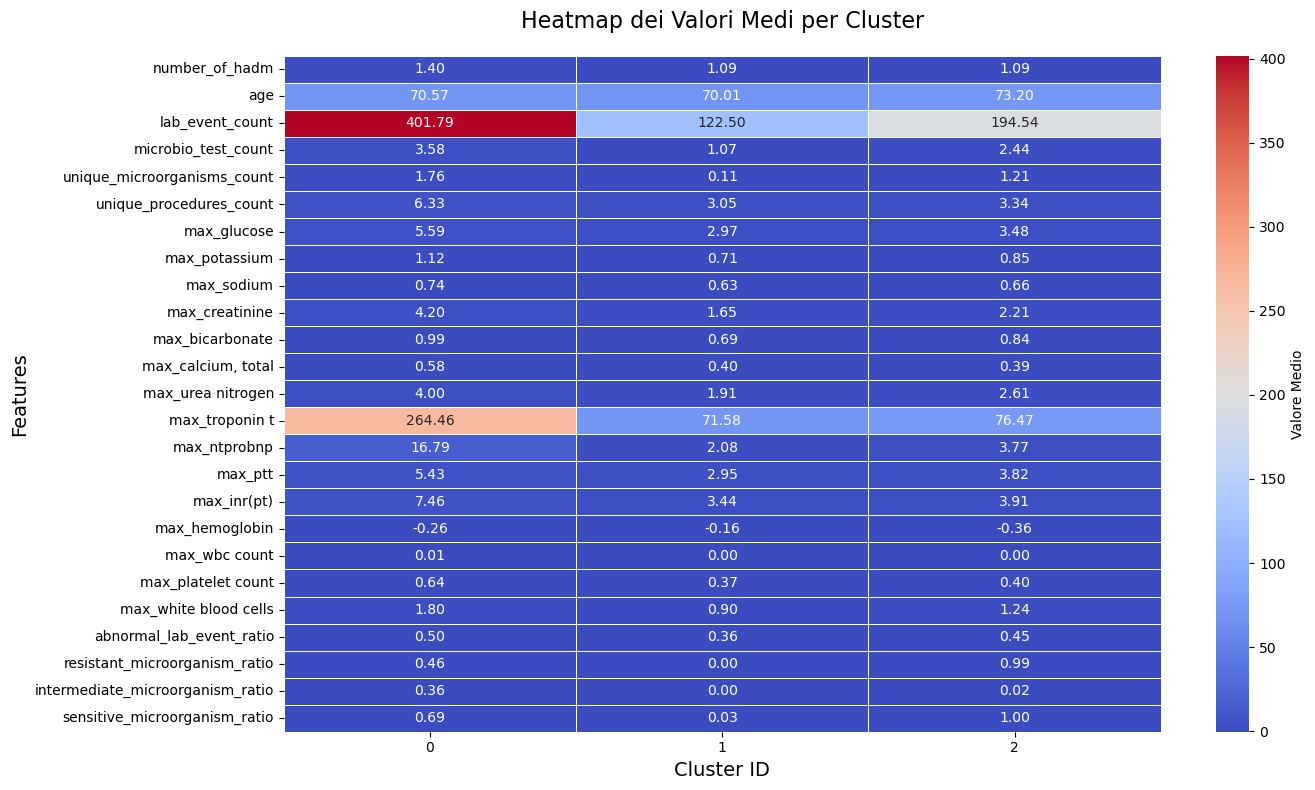

In [125]:
# 3. Confronto tra cluster - Heatmap delle medie
plt.figure(figsize=(14, 8))

# Calcola le medie per ogni cluster
cluster_means = profile_df.groupby('cluster')[numeric_cols_analysis].mean()

# Crea la heatmap
sns.heatmap(cluster_means.T, annot=True, fmt='.2f', cmap='coolwarm', 
            cbar_kws={'label': 'Valore Medio'}, linewidths=0.5)
plt.title('Heatmap dei Valori Medi per Cluster', fontsize=16, pad=20)
plt.xlabel('Cluster ID', fontsize=14)
plt.ylabel('Features', fontsize=14)
plt.tight_layout()
plt.show()

### Interpretazione della Heatmap

La heatmap mostra i **valori medi** di ogni feature per ciascun cluster:

- **Colori caldi (rosso/arancione)**: valori più alti della feature
- **Colori freddi (blu)**: valori più bassi della feature
- **Righe**: rappresentano le diverse features (variabili)
- **Colonne**: rappresentano i diversi cluster

**Come leggere la heatmap:**
1. Confronta **orizzontalmente** (lungo una riga) per vedere come una specifica feature varia tra i cluster
2. Confronta **verticalmente** (lungo una colonna) per vedere il profilo completo di un cluster
3. I cluster con **pattern di colori simili** hanno caratteristiche simili
4. Le **differenze marcate di colore** indicano caratteristiche distintive di un cluster

In [126]:
#percentage of each desease in each cluster
disease_cols = ['ACS_acute_ischemic','Chronic_ischemic','Heart_failure','Valvular_nonrheumatic','Myocarditis_or_cardiomyopathy','Pericardial_disease','Endocarditis','Cardiac_arrest','Arrhythmias_or_conduction']
disease_summary = profile_df.groupby('cluster')[disease_cols].mean() * 100  
disease_summary

,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction
cluster,,,,,,,,,
0,41.711230,9.625668,42.780749,5.882353,0.534759,5.882353,0.000000,0.000000,8.556150
1,32.236040,14.752499,28.846623,5.925384,1.170446,5.267008,0.902219,0.024384,15.288954
2,30.526316,7.368421,33.684211,15.789474,0.000000,3.157895,1.052632,1.052632,13.684211


### non riuscuiamo ad individuare una distinzione delle patalogie

In [111]:
#  valori della troponina in ogni cluster
troponin_summary = profile_df.groupby('cluster')['max_troponin t'].describe()
troponin_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,187.0,264.459893,574.033027,0.0,2.0,18.0,180.0,4130.0
0,4101.0,71.577664,211.284839,0.0,0.0,2.0,33.0,2445.0
1,95.0,76.473684,237.087731,0.0,0.0,3.0,34.0,1982.0


### i valore della troponina nel cluster NOISE è decidamente più elevato: casi clinici più gravi

In [114]:
# lab events count  per cluster
lab_events_summary = profile_df.groupby('cluster')['lab_event_count'].describe()
lab_events_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,187.0,401.786096,350.311178,20.0,175.5,273.0,584.5,2221.0
0,4101.0,122.503048,109.885711,0.0,52.0,89.0,158.0,1376.0
1,95.0,194.536842,131.075000,17.0,104.0,154.0,242.5,632.0


### nel cluster del noise ci sono i pazienti con più osservazioni: clinicamnte piu gravi